# BƯỚC 5: DỮ LIỆU TƯƠNG TÁC MÔ PHỎNG & MATRIX FACTORIZATION (COLLABORATIVE FILTERING)

Notebook 05 xây hệ gợi ý **dựa trên nội dung (CBF)**. Bước tự nhiên tiếp theo là **lọc cộng tác (CF)**: học từ *hành vi* của nhiều người dùng ("người giống bạn đã ứng tuyển vào...") thay vì chỉ từ nội dung tin. Vấn đề: dự án **chưa có log tương tác thật** (click, lưu, ứng tuyển). Notebook này:

1. **Sinh bộ dữ liệu tương tác mô phỏng** dựa trên các tin IT thật trong `jobs_clean.csv` (do notebook 02 sinh ra; crawl thêm và chạy lại notebook 02 thì notebook này tự dùng dữ liệu mới);
2. Huấn luyện **Matrix Factorization cho phản hồi ngầm (ALS)** và các mô hình đối chứng;
3. So sánh **CBF ↔ CF ↔ Hybrid** dưới các giả định khác nhau.

### Vì sao không dùng lại bộ mô phỏng cũ (`_archive/collaborative_filtering/synthetic_data.py`)?
| Vấn đề của bản cũ | Hậu quả | Cách làm ở đây |
|---|---|---|
| Tương tác sinh **chỉ từ khớp kỹ năng / cấp bậc / thành phố**, đúng những gì CBF dùng | CF chỉ học lại CBF, phép so sánh vòng tròn, không kết luận được gì | Mức độ thích = phần **nội dung** (CBF thấy) + phần **ẩn** (loại công ty, thương hiệu, độ hấp dẫn của tin) mà chỉ hành vi mới lộ ra; tỷ trọng điều chỉnh bằng $\alpha$ |
| Tên kỹ năng không chuẩn (`Spring`, `HTML`, `Kafka`) | Không khớp với `required_skills` đã chuẩn hóa | Kỹ năng người dùng lấy mẫu **từ chính kho kỹ năng của tin thật** |
| Người dùng "chọn" từ toàn bộ kho, không có lượt hiển thị | Không có mẫu âm thật, không có thiên lệch vị trí | Mô phỏng **phiên**: mỗi phiên chỉ thấy 20 tin, có thiên lệch vị trí, lưu cả lượt hiển thị không bấm |
| Thời gian ngẫu nhiên | Không chia train/test theo thời gian được | Tin chỉ được tương tác khi **còn mở** (theo `deadline`); chia tập theo thời gian |
| `TruncatedSVD` coi ô trống là "ghét" | Sai với phản hồi ngầm | **ALS cho phản hồi ngầm** (Hu, Koren, Volinsky 2008), có so sánh với SVD |

> **Giới hạn quan trọng:** đây là dữ liệu **mô phỏng**. Mọi kết luận chỉ đúng *dưới các giả định của bộ mô phỏng*; vì vậy notebook công bố đủ tham số và quét $\alpha$ (phân tích độ nhạy) thay vì báo một con số duy nhất.

## 1. Nạp dữ liệu tin tuyển dụng IT

In [2]:
import os, re, json, time, unicodedata
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as l2_normalize

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)

DATA_PATH = os.path.abspath(os.path.join('..', '..', 'data', 'notebook', 'content_base', 'jobs_clean.csv'))
OUT_DIR = os.path.abspath(os.path.join('..', '..', 'data', 'simulated'))
SEED = 42

jobs_all = pd.read_csv(DATA_PATH)
missing = {'is_it', 'required_skills', 'deadline'} - set(jobs_all.columns)
if missing:
    raise ValueError(f"jobs_clean.csv thiếu cột {missing}: hãy chạy lại notebook 02 trước.")
jobs = jobs_all[jobs_all['is_it'] == True].reset_index(drop=True)
jobs['skills'] = jobs['required_skills'].fillna('').map(lambda s: [x.strip() for x in s.split(',') if x.strip()])
print(f"Đã nạp {len(jobs):,} tin IT / {len(jobs_all):,} tin sạch, {jobs['company_name'].nunique():,} công ty")

Đã nạp 3,470 tin IT / 5,111 tin sạch, 1,639 công ty


### 1.1. Nhóm nghề và vòng đời của từng tin
- **Nhóm nghề**: suy từ tiêu đề bằng cùng bộ từ khóa với notebook 05 (mục 8), mỗi tin lấy nhóm khớp đầu tiên theo thứ tự ưu tiên.
- **Vòng đời**: dữ liệu chỉ có `deadline`, nên coi mỗi tin **mở 45 ngày trước hạn nộp**. Giai đoạn mô phỏng là 55 ngày, kết thúc ở **ngày chụp dữ liệu**; tin chỉ có thể được hiển thị khi đang mở.
- **Ngày chụp dữ liệu** được suy ra từ chính file, không ghi cứng: notebook 02 gắn `is_active = deadline ≥ ngày chạy`, nên ngày chạy nằm ngay sau hạn nộp muộn nhất của các tin đã hết hạn. Nhờ vậy khi crawl thêm và chạy lại notebook 02, khung thời gian tự dịch theo.
- Khi crawl tích lũy nhiều đợt, kho có cả tin **đã đóng từ lâu**; các tin không mở ngày nào trong giai đoạn mô phỏng bị bỏ.

In [3]:
def strip_accents(text):
    s = unicodedata.normalize('NFD', str(text).lower().replace('đ', 'd'))
    return ''.join(c for c in s if unicodedata.category(c) != 'Mn')

DOMAIN_PATTERNS = {   # thứ tự = ưu tiên khi một tiêu đề khớp nhiều nhóm
    "QA/QC": r"\bqa\b|\bqc\b|test|kiem thu|chat luong|quality",
    "Data/AI": r"\bdata\b|\bai\b|machine learning|\bml\b|\bbi\b|analytics|du lieu|scientist|\bnlp\b|\bllm\b|computer vision",
    "Frontend/Mobile": r"front.?end|react|angular|\bvue|mobile|\bios\b|android|flutter|swift|kotlin|web developer|lap trinh web",
    "DevOps/Cloud": r"devops|cloud|\bsre\b|\bsystem|he thong|ha tang|infrastructure|linux|security|an toan thong tin|an ninh|network|\bmang\b|quan tri",
    "Backend": r"back.?end|\bjava\b|python|\bphp\b|\.net|dotnet|\bnode|golang|\bgo\b|ruby|\bc#|c\+\+|lap trinh vien|software (engineer|developer)|ky su phan mem",
}
DOMAINS = list(DOMAIN_PATTERNS)

def job_domain(title):
    t = strip_accents(title)
    for d, p in DOMAIN_PATTERNS.items():
        if re.search(p, t):
            return d
    return "Khác"

jobs['domain'] = jobs['title'].map(job_domain)

def infer_snapshot(df):
    """Ngày notebook 02 tính is_active: ngay sau hạn nộp muộn nhất của tin đã hết hạn (hoặc hạn sớm nhất của tin còn hạn)."""
    dl = pd.to_datetime(df['deadline'], errors='coerce')
    expired, active = dl[~df['is_active'].astype(bool)].dropna(), dl[df['is_active'].astype(bool)].dropna()
    if len(expired):
        return expired.max() + pd.Timedelta(days=1)
    return active.min() if len(active) else pd.Timestamp.now().normalize()

SNAPSHOT = infer_snapshot(jobs)
N_DAYS, JOB_OPEN_DAYS = 55, 45
DAY0 = SNAPSHOT - pd.Timedelta(days=N_DAYS)
deadline_day = (pd.to_datetime(jobs['deadline'], errors='coerce') - DAY0).dt.days
n_before = len(jobs)
jobs = jobs[deadline_day.notna() & (deadline_day >= 0)].reset_index(drop=True)      # bỏ tin đã đóng trước giai đoạn mô phỏng
deadline_day = deadline_day[deadline_day.notna() & (deadline_day >= 0)].values.astype(int)
jobs['open_day'] = np.clip(deadline_day - JOB_OPEN_DAYS, 0, N_DAYS)
jobs['close_day'] = np.clip(deadline_day, 0, N_DAYS)

print(f"Ngày chụp dữ liệu (suy từ file): {SNAPSHOT.date()} | giữ {len(jobs):,}/{n_before:,} tin có mở trong giai đoạn mô phỏng")
print("Phân bố nhóm nghề:", jobs['domain'].value_counts().to_dict())
print(f"Giai đoạn mô phỏng: {DAY0.date()} ➔ {SNAPSHOT.date()} ({N_DAYS} ngày)")
print(f"Số tin đang mở trung bình mỗi ngày: {np.mean([((jobs.open_day <= d) & (jobs.close_day >= d)).sum() for d in range(N_DAYS)]):,.0f}")

Ngày chụp dữ liệu (suy từ file): 2026-11-05 | giữ 3,470/3,470 tin có mở trong giai đoạn mô phỏng
Phân bố nhóm nghề: {'Khác': 1593, 'DevOps/Cloud': 659, 'Data/AI': 534, 'QA/QC': 290, 'Backend': 239, 'Frontend/Mobile': 155}
Giai đoạn mô phỏng: 2026-09-11 ➔ 2026-11-05 (55 ngày)
Số tin đang mở trung bình mỗi ngày: 2,176


## 2. Sinh bộ dữ liệu mô phỏng

### 2.1. Thuộc tính ẩn của tin & công ty (mô hình KHÔNG được thấy)
Đây là thứ có thật trên thị trường nhưng **không nằm trong nội dung tin**, nên CBF không thể biết; chỉ hành vi của nhiều người mới để lộ ra:
- **Loại công ty** (4 loại: Startup, Product, Outsourcing, Tài chính/Doanh nghiệp lớn): gán ngẫu nhiên cho mỗi công ty.
- **Sức hút thương hiệu** của công ty: $b_c \sim \mathcal{N}(0, 1)$.
- **Độ hấp dẫn riêng** của tin (phúc lợi, dự án, đánh giá...): $q_j \sim \mathcal{N}(0, 0{,}5^2)$.

In [4]:
rng = np.random.default_rng(SEED)
COMPANY_TYPES = ['Startup', 'Product', 'Outsourcing', 'Tài chính / DN lớn']
companies = jobs['company_name'].fillna('?').unique()
company_type = dict(zip(companies, rng.choice(len(COMPANY_TYPES), size=len(companies), p=[0.2, 0.25, 0.35, 0.2])))
company_brand = dict(zip(companies, rng.normal(0, 1, len(companies))))
jobs['company_type'] = jobs['company_name'].fillna('?').map(company_type)
jobs['brand'] = jobs['company_name'].fillna('?').map(company_brand)
jobs['quality'] = rng.normal(0, 0.5, len(jobs))
print(jobs['company_type'].map(dict(enumerate(COMPANY_TYPES))).value_counts().to_string())

company_type
Outsourcing           1254
Product                843
Startup                688
Tài chính / DN lớn     685


### 2.2. Người dùng mô phỏng
Mỗi người dùng có **phần quan sát được** (thứ họ khai trong hồ sơ, CBF dùng được) và **phần ẩn** (khẩu vị, chỉ lộ qua hành vi):

| Thuộc tính | Cách sinh |
|---|---|
| Nhóm nghề | theo tỷ lệ tin của từng nhóm trong kho |
| Kỹ năng (3-7) | lấy mẫu từ **kỹ năng thật** của các tin cùng nhóm, kỹ năng phổ biến được chọn nhiều hơn |
| Kinh nghiệm | lấy mẫu từ yêu cầu kinh nghiệm của tin cùng nhóm, cộng thêm 0-2 năm |
| Thành phố | Hà Nội / Hồ Chí Minh / Đà Nẵng theo tỷ lệ tin, 10% chọn "Tất cả" |
| Mức hoạt động | số phiên ~ Poisson với trung bình lấy từ phân bố log-normal (ít người rất tích cực, nhiều người ít hoạt động) |
| **Khẩu vị loại công ty** *(ẩn)* | người dùng thuộc 1 trong 6 **cụm khẩu vị**; mỗi cụm thích các loại công ty khác nhau. Cấu trúc cụm này là thứ CF có thể khai thác |
| **Độ nhạy thương hiệu** *(ẩn)* | $\sim U(0, 1)$ |

In [5]:
N_USERS = 3000
N_TASTE_CLUSTERS = 6
skill_freq = {d: pd.Series([s for sk in jobs.loc[jobs.domain == d, 'skills'] for s in sk]).value_counts() for d in DOMAINS}
dom_share = jobs.loc[jobs.domain != 'Khác', 'domain'].value_counts(normalize=True)
city_share = jobs.loc[jobs.city.isin(['Hà Nội', 'Hồ Chí Minh', 'Đà Nẵng']), 'city'].value_counts(normalize=True)
cluster_taste = rng.dirichlet([0.4] * len(COMPANY_TYPES), size=N_TASTE_CLUSTERS)    # mỗi cụm: phân bố khẩu vị 4 loại công ty

users = []
for u in range(N_USERS):
    d = rng.choice(dom_share.index, p=dom_share.values)
    freq = skill_freq[d]
    k = int(rng.integers(3, 8))
    p = freq.values ** 0.7; p = p / p.sum()
    skills = list(rng.choice(freq.index, size=min(k, len(freq)), replace=False, p=p))
    exp_pool = jobs.loc[jobs.domain == d, 'experience_min'].dropna().values
    cl = int(rng.integers(N_TASTE_CLUSTERS))
    taste = cluster_taste[cl] * 0.8 + rng.dirichlet([1] * len(COMPANY_TYPES)) * 0.2
    users.append({
        'user_id': u, 'domain': d, 'skills': skills,
        'exp': float(np.clip(rng.choice(exp_pool) + rng.uniform(0, 2), 0, 15)),
        'city': 'Tất cả' if rng.random() < 0.10 else rng.choice(city_share.index, p=city_share.values),
        'activity': float(rng.lognormal(np.log(5), 0.8)),
        'taste_cluster': cl, 'taste': taste, 'brand_sens': float(rng.uniform(0, 1)),
    })
users = pd.DataFrame(users)
print(f"{len(users):,} người dùng mô phỏng")
print("Theo nhóm nghề:", users['domain'].value_counts().to_dict())
display(users[['user_id', 'domain', 'skills', 'exp', 'city', 'activity', 'taste_cluster']].head(5))

3,000 người dùng mô phỏng
Theo nhóm nghề: {'DevOps/Cloud': 1045, 'Data/AI': 855, 'QA/QC': 474, 'Backend': 393, 'Frontend/Mobile': 233}


,user_id,domain,skills,exp,city,activity,taste_cluster
0,0,Data/AI,"[Data Management, Snowflake, NumPy, Apache Air...",2.193161,Hồ Chí Minh,1.964497,4
1,1,QA/QC,"[React, Cypress, Swift, Jira, TypeScript]",3.818248,Hà Nội,9.069933,2
2,2,DevOps/Cloud,"[Jenkins, CI/CD, PostgreSQL, Oracle Database, ...",3.572073,Hồ Chí Minh,9.316484,3
3,3,QA/QC,"[API Testing, TypeScript, Cypress]",2.813910,Hồ Chí Minh,32.655861,4
4,4,Data/AI,"[System Administration, Embedded, Linux, SQL S...",3.011002,Hà Nội,9.058466,5


### 2.3. Mức độ thích thật $U(u, j)$ (ground truth)

$$U_\alpha(u, j) = \alpha \cdot z\big(\text{Nội dung}(u, j)\big) + (1 - \alpha) \cdot z\big(\text{Ẩn}(u, j)\big)$$

- **Nội dung** (CBF quan sát được): $0{,}45 \cdot$ khớp kỹ năng $+ 0{,}25 \cdot$ đúng nhóm nghề $+ 0{,}15 \cdot$ đủ kinh nghiệm $+ 0{,}15 \cdot$ đúng thành phố. Khớp kỹ năng $= \frac{|S_u \cap S_j|}{\sqrt{|S_u| \cdot |S_j|}}$.
- **Ẩn**: $\text{khẩu vị}_u[\text{loại công ty}_j] \cdot 3 + \text{độ nhạy thương hiệu}_u \cdot b_c + q_j$.
- $z(\cdot)$: chuẩn hóa về trung bình 0, độ lệch chuẩn 1 để hai phần có cùng thang đo; $\alpha$ là **núm vặn** của thí nghiệm.

Phần ẩn được sinh **từ cụm khẩu vị + thương hiệu**, *không phải* tích hai vector ngẫu nhiên. Nếu sinh đúng dạng "tích vector", Matrix Factorization sẽ khớp hoàn hảo với cơ chế sinh và thắng một cách dễ dãi.

In [6]:
skill_vocab = {s: i for i, s in enumerate(sorted({s for sk in jobs['skills'] for s in sk}))}

def skill_matrix(skill_lists):
    rows, cols = [], []
    for r, sk in enumerate(skill_lists):
        for s in sk:
            if s in skill_vocab:
                rows.append(r); cols.append(skill_vocab[s])
    return sp.csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(skill_lists), len(skill_vocab)))

SU, SJ = skill_matrix(users['skills']), skill_matrix(jobs['skills'])
overlap = (SU @ SJ.T).toarray()
denom = np.sqrt(np.outer(np.asarray(SU.sum(1)).ravel(), np.asarray(SJ.sum(1)).ravel()))
skill_fit = np.divide(overlap, denom, out=np.zeros_like(overlap), where=denom > 0)

domain_fit = (users['domain'].to_numpy(dtype=object)[:, None] == jobs['domain'].to_numpy(dtype=object)[None, :]).astype(np.float32)
job_exp = jobs['experience_min'].fillna(0).values
exp_fit = np.clip(1 - np.maximum(job_exp[None, :] - users['exp'].values[:, None], 0) / 3, 0, 1)
ucity, jcity = users['city'].to_numpy(dtype=object)[:, None], jobs['city'].to_numpy(dtype=object)[None, :]
city_fit = np.where((ucity == 'Tất cả') | (ucity == jcity) | (jcity == 'Toàn quốc'), 1.0, 0.2)
content = 0.45 * skill_fit + 0.25 * domain_fit + 0.15 * exp_fit + 0.15 * city_fit

taste = np.stack(users['taste'].values)                                   # (n_users, 4)
hidden = (taste[:, jobs['company_type'].values] * 3
          + users['brand_sens'].values[:, None] * jobs['brand'].values[None, :]
          + jobs['quality'].values[None, :])

zscore = lambda M: ((M - M.mean()) / M.std()).astype(np.float32)
Z_CONTENT, Z_HIDDEN = zscore(content), zscore(hidden)
del overlap, denom, skill_fit, domain_fit, exp_fit, city_fit, content, hidden

def true_utility(alpha):
    return alpha * Z_CONTENT + (1 - alpha) * Z_HIDDEN

print("Ma trận U(u, j):", Z_CONTENT.shape, "| tương quan Nội dung ↔ Ẩn:",
      round(float(np.corrcoef(Z_CONTENT.ravel()[::97], Z_HIDDEN.ravel()[::97])[0, 1]), 3))

Ma trận U(u, j): (3000, 3470) | tương quan Nội dung ↔ Ẩn: -0.01


### 2.4. Mô phỏng phiên: người dùng chỉ thấy một phần nhỏ kho tin

Mỗi phiên (một ngày ngẫu nhiên), người dùng thấy **20 tin đang mở**:

| Nguồn | Số tin | Ý nghĩa |
|---|---|---|
| Tìm kiếm | 10 | tin cùng nhóm nghề, chọn ngẫu nhiên (mô phỏng gõ từ khóa) |
| Gợi ý của hệ thống | 6 | lấy từ top-30 theo **điểm nội dung có nhiễu** (mô phỏng một hệ CBF đang chạy) |
| Khám phá | 4 | ngẫu nhiên trong toàn kho đang mở |

Thứ tự hiển thị được xáo trộn, rồi áp dụng **phễu hành vi**:
- Xem tới vị trí $k$ với xác suất $1/\log_2(k + 2)$ (*thiên lệch vị trí*: tin ở trên được chú ý nhiều hơn);
- **Bấm xem** $\sim \sigma(2U - 4)$; nếu đã bấm: **lưu** $\sim \sigma(U - 3)$, **ứng tuyển** $\sim \sigma(U - 4)$.

Các hằng số được hiệu chỉnh để tỷ lệ bấm khoảng 5-6% số lượt hiển thị, và trong số lượt bấm thì phần lớn chỉ xem, ít người lưu, ứng tuyển hiếm nhất (xem mục 2.5).

Bước hiển thị **không phụ thuộc $\alpha$**, và các số ngẫu nhiên của phễu được sinh **một lần** rồi dùng chung cho mọi $\alpha$ (*common random numbers*). Nhờ vậy khác biệt giữa các mức $\alpha$ chỉ đến từ $\alpha$, không phải từ may rủi.

In [7]:
SLATE = {'search': 10, 'feed': 6, 'explore': 4}
open_d, close_d = jobs['open_day'].values, jobs['close_day'].values
job_dom = jobs['domain'].to_numpy(dtype=object)

t0 = time.time()
imp = []   # (user, job, day, position, source)
for u in users.itertuples():
    n_sessions = max(1, rng.poisson(u.activity))
    for day in np.sort(rng.integers(0, N_DAYS, size=n_sessions)):
        alive = np.flatnonzero((open_d <= day) & (close_d >= day))
        same = alive[job_dom[alive] == u.domain]
        picks = []
        if len(same):
            picks += [(j, 'search') for j in rng.choice(same, size=min(SLATE['search'], len(same)), replace=False)]
        noisy = Z_CONTENT[u.user_id, alive] + rng.normal(0, 0.3, len(alive))
        top = alive[np.argsort(-noisy)[:30]]
        picks += [(j, 'feed') for j in rng.choice(top, size=SLATE['feed'], replace=False)]
        picks += [(j, 'explore') for j in rng.choice(alive, size=SLATE['explore'], replace=False)]
        seen, slate = set(), []
        for j, src in picks:                       # bỏ tin trùng trong cùng một phiên
            if j not in seen:
                seen.add(j); slate.append((j, src))
        order = rng.permutation(len(slate))
        for pos, k in enumerate(order):
            imp.append((u.user_id, slate[k][0], day, pos, slate[k][1]))

impressions = pd.DataFrame(imp, columns=['user_id', 'job_idx', 'day', 'position', 'source'])
n = len(impressions)
impressions['r_examine'], impressions['r_click'], impressions['r_save'], impressions['r_apply'] = rng.random((4, n)).astype(np.float32)
print(f"{n:,} lượt hiển thị trong {impressions.groupby(['user_id', 'day']).ngroups:,} phiên ({time.time() - t0:.1f}s)")

418,545 lượt hiển thị trong 19,083 phiên (4.0s)


In [8]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))
EVENT_WEIGHT = {'click': 1.0, 'save': 3.0, 'apply': 5.0}
FUNNEL = {'click': (2.0, -4.0), 'save': (1.0, -3.0), 'apply': (1.0, -4.0)}   # (hệ số của U, hằng số) trong σ(a·U + b)

def simulate_events(alpha):
    """Áp dụng phễu hành vi lên các lượt hiển thị ➔ bảng sự kiện (mỗi lượt hiển thị tối đa 1 sự kiện: hành động sâu nhất)."""
    Ua = true_utility(alpha)[impressions['user_id'].values, impressions['job_idx'].values]
    examined = impressions['r_examine'].values < 1 / np.log2(impressions['position'].values + 2)
    p = {e: sigmoid(a * Ua + b) for e, (a, b) in FUNNEL.items()}
    click = examined & (impressions['r_click'].values < p['click'])
    save = click & (impressions['r_save'].values < p['save'])
    apply_ = click & (impressions['r_apply'].values < p['apply'])
    ev = impressions.loc[click, ['user_id', 'job_idx', 'day', 'position', 'source']].copy()
    ev['event'] = np.where(apply_[click], 'apply', np.where(save[click], 'save', 'click'))
    ev['weight'] = ev['event'].map(EVENT_WEIGHT)
    return ev.reset_index(drop=True)

events_05 = simulate_events(0.5)
print(f"α = 0,5: {len(events_05):,} sự kiện | " + ", ".join(f"{k}: {v:,}" for k, v in events_05['event'].value_counts().items()))

α = 0,5: 24,581 sự kiện | click: 17,725, save: 4,547, apply: 2,309


### 2.5. Kiểm tra độ giống thực tế
Một bộ mô phỏng tốt cần có các đặc điểm điển hình của log thật: **rất thưa**, **đuôi dài** (ít tin nhận phần lớn tương tác, ít người dùng rất tích cực), tỷ lệ bấm thấp và ứng tuyển còn thấp hơn.

,"α = 0,5"
Tỷ lệ bấm / hiển thị (CTR),5.9%
Tỷ lệ ứng tuyển / hiển thị,0.55%
Trong số lượt bấm: chỉ xem / lưu / ứng tuyển,72% / 18% / 9%
Độ thưa ma trận user × job,99.780%
Sự kiện / người dùng (trung vị; P90),6; 18
Người dùng không có sự kiện nào,6.3%
10% tin phổ biến nhất chiếm,45.4% sự kiện
Tin chưa từng được bấm,37.9%


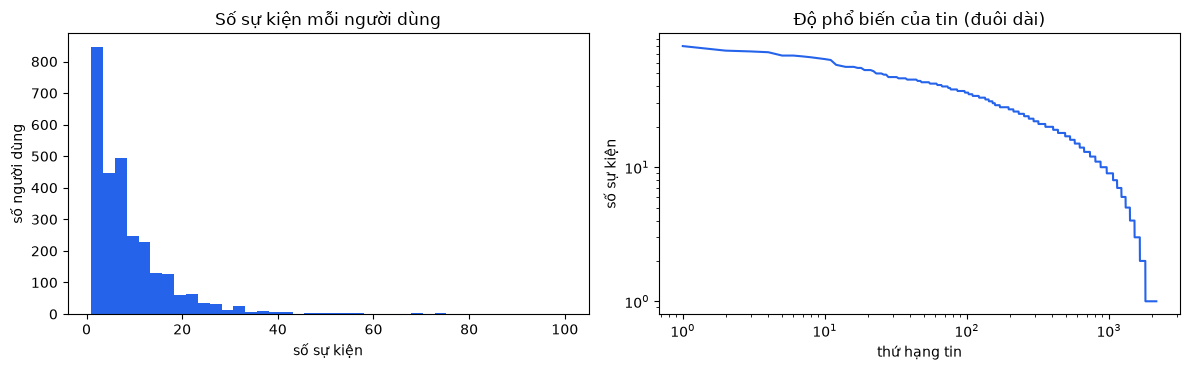

In [9]:
def realism_report(ev):
    pairs = ev.groupby(['user_id', 'job_idx']).size()
    per_user = ev.groupby('user_id').size().reindex(range(N_USERS), fill_value=0)
    per_job = ev.groupby('job_idx').size().reindex(range(len(jobs)), fill_value=0).sort_values(ascending=False)
    top10 = per_job.iloc[:len(per_job) // 10].sum() / per_job.sum()
    return {
        'Tỷ lệ bấm / hiển thị (CTR)': f"{len(ev) / len(impressions):.1%}",
        'Tỷ lệ ứng tuyển / hiển thị': f"{(ev.event == 'apply').sum() / len(impressions):.2%}",
        'Trong số lượt bấm: chỉ xem / lưu / ứng tuyển': ' / '.join(f"{ev.event.eq(e).mean():.0%}" for e in ['click', 'save', 'apply']),
        'Độ thưa ma trận user × job': f"{1 - len(pairs) / (N_USERS * len(jobs)):.3%}",
        'Sự kiện / người dùng (trung vị; P90)': f"{per_user.median():.0f}; {per_user.quantile(0.9):.0f}",
        'Người dùng không có sự kiện nào': f"{(per_user == 0).mean():.1%}",
        '10% tin phổ biến nhất chiếm': f"{top10:.1%} sự kiện",
        'Tin chưa từng được bấm': f"{(per_job == 0).mean():.1%}",
    }

display(pd.Series(realism_report(events_05), name='α = 0,5').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
events_05.groupby('user_id').size().plot.hist(bins=40, ax=axes[0], color='#2563eb')
axes[0].set(title='Số sự kiện mỗi người dùng', xlabel='số sự kiện', ylabel='số người dùng')
pj = events_05.groupby('job_idx').size().sort_values(ascending=False).values
axes[1].plot(np.arange(1, len(pj) + 1), pj, color='#2563eb')
axes[1].set(title='Độ phổ biến của tin (đuôi dài)', xlabel='thứ hạng tin', ylabel='số sự kiện', xscale='log', yscale='log')
plt.tight_layout(); plt.show()

## 3. Thiết lập đánh giá

- **Chia theo thời gian**: train = sự kiện trước ngày 45, test = 10 ngày cuối. Không chia ngẫu nhiên vì như vậy mô hình được "nhìn thấy tương lai".
- **Validation**: để chọn tham số mà không "nhìn" tập test, dùng thêm một lần chia sớm hơn: train = trước ngày 38, validation = ngày 38-44.
- **Người dùng được đánh giá**: có ít nhất 1 sự kiện ở train và 1 sự kiện ở test.
- **Ứng viên**: các tin còn mở trong giai đoạn test, bỏ các tin người dùng đã tương tác ở train.
- **Chỉ số**:
  - **Recall@10, NDCG@10** so với sự kiện test (lợi ích: bấm = 1, lưu = 2, ứng tuyển = 3), giống cách đánh giá trên log thật;
  - **Oracle-P@10**: tỷ lệ tin gợi ý nằm trong **top-10 theo mức độ thích thật** $U(u, j)$. Chỉ đo được nhờ mô phỏng, và không bị giới hạn bởi việc người dùng chỉ thấy một phần kho;
  - **Recall@10 trên tin mới** (*cold-start*): chỉ tính các sự kiện test vào tin **chưa có tương tác nào ở train**;
  - **Độ phủ**: phần trăm tin ứng viên xuất hiện trong ít nhất một danh sách gợi ý.

In [10]:
VAL_START, TEST_START, K = 38, 45, 10
n_items = len(jobs)

def build_split(ev, start=TEST_START, end=N_DAYS + 1):
    """Train = sự kiện trước ngày `start`; đánh giá = sự kiện trong [start, end)."""
    tr, te = ev[ev.day < start], ev[(ev.day >= start) & (ev.day < end)]
    R = (tr.groupby(['user_id', 'job_idx'])['weight'].max().reset_index())
    R = sp.csr_matrix((R['weight'].values.astype(np.float32), (R['user_id'].values, R['job_idx'].values)), shape=(N_USERS, n_items))
    gains = te.assign(g=te['event'].map({'click': 1, 'save': 2, 'apply': 3})).groupby(['user_id', 'job_idx'])['g'].max()
    eval_users = np.array(sorted(set(te.user_id) & set(tr.user_id)))
    cand = (close_d >= start) & (open_d < end)                         # tin còn mở trong giai đoạn đánh giá
    warm_items = np.asarray((R > 0).sum(0)).ravel() > 0
    return {'R': R, 'gains': gains, 'eval_users': eval_users, 'cand': cand, 'warm_items': warm_items}

def evaluate(scores, split, U_true):
    """scores: (len(eval_users), n_items). Trả về các chỉ số trung bình."""
    R, cand, warm = split['R'], split['cand'], split['warm_items']
    rec, ndcg, orac, cold_hit, cold_tot, covered = [], [], [], 0, 0, set()
    disc = 1 / np.log2(np.arange(2, K + 2))
    for row, u in enumerate(split['eval_users']):
        mask = cand.copy(); mask[R[u].indices] = False
        s = np.where(mask, scores[row], -np.inf)
        top = np.argpartition(-s, K)[:K]; top = top[np.argsort(-s[top])]
        covered.update(top.tolist())
        g = split['gains'].loc[u]
        pos = {int(j): v for j, v in g.items() if mask[int(j)]}
        if pos:
            hit = [pos.get(int(j), 0) for j in top]
            rec.append(sum(h > 0 for h in hit) / min(K, len(pos)))
            ideal = sorted(pos.values(), reverse=True)[:K]
            ndcg.append(np.sum((2 ** np.array(hit) - 1) * disc) / np.sum((2 ** np.array(ideal) - 1) * disc[:len(ideal)]))
            cold = [j for j in pos if not warm[j]]
            cold_tot += len(cold); cold_hit += len(set(cold) & set(top.tolist()))
        ut = np.where(mask, U_true[u], -np.inf)
        orac.append(len(set(top.tolist()) & set(np.argpartition(-ut, K)[:K].tolist())) / K)
    return {'Recall@10': np.mean(rec), 'NDCG@10': np.mean(ndcg), 'Oracle-P@10': np.mean(orac),
            'Recall@10 tin mới': cold_hit / cold_tot if cold_tot else np.nan, 'Độ phủ': len(covered) / cand.sum()}

split_05 = build_split(events_05)
val_05 = build_split(events_05, VAL_START, TEST_START)
print(f"Train: {split_05['R'].nnz:,} cặp user-job | người dùng đánh giá: {len(split_05['eval_users']):,} | "
      f"tin ứng viên: {split_05['cand'].sum():,}, trong đó {(~split_05['warm_items'] & split_05['cand']).sum():,} tin chưa có tương tác ở train")

Train: 18,551 cặp user-job | người dùng đánh giá: 1,435 | tin ứng viên: 2,985, trong đó 1,294 tin chưa có tương tác ở train


## 4. Các mô hình

| Mô hình | Loại | Ý tưởng |
|---|---|---|
| **Phổ biến** | đối chứng | tin được tương tác nhiều nhất ở train |
| **ItemKNN** | CF theo láng giềng | tin giống các tin bạn đã tương tác (cosine trên cột ma trận tương tác) |
| **SVD** | MF *sai cách* | `TruncatedSVD` coi mọi ô trống là 0 = "không thích" (cách của bản cũ) |
| **ALS** | **MF cho phản hồi ngầm** | ô trống = "chưa biết", độ tin cậy $c_{uj} = 1 + a \cdot w_{uj}$ (bấm 1, lưu 3, ứng tuyển 5) |
| **CBF** | nội dung | bản rút gọn của notebook 05: TF-IDF (tiêu đề + kỹ năng) so với kỹ năng hồ sơ, cộng điểm kinh nghiệm và thành phố |
| **Hybrid** | kết hợp | $w \cdot z(\text{CBF}) + (1 - w) \cdot z(\text{ALS})$, chuẩn hóa z-score theo từng người dùng. Tin **chưa có tương tác** (ALS không biết) chỉ dùng $z(\text{CBF})$, cùng quy tắc "thiếu dữ liệu thì bỏ thành phần" như notebook 05 |

### 4.1. ALS cho phản hồi ngầm (Hu, Koren & Volinsky, 2008)
Tìm $x_u, y_j \in \mathbb{R}^k$ tối thiểu hóa $\sum_{u,j} c_{uj}(p_{uj} - x_u^\top y_j)^2 + \lambda(\|x_u\|^2 + \|y_j\|^2)$ với $p_{uj} = 1$ nếu có tương tác. Cố định $Y$ thì nghiệm của $x_u$ có dạng đóng:
$$x_u = (Y^\top Y + Y^\top (C_u - I) Y + \lambda I)^{-1} Y^\top C_u p_u$$
Mẹo tính nhanh: $Y^\top Y$ dùng chung cho mọi người dùng, phần $Y^\top (C_u - I) Y$ chỉ cần tính trên các tin người dùng đã tương tác. Tin **chưa có tương tác** nào có $y_j = 0$ ➔ điểm 0: đây chính là điểm yếu *cold-start* của MF.

In [11]:
def als_implicit(R, k=16, reg=1.0, alpha_conf=1.0, iters=12, seed=0):
    rng_ = np.random.default_rng(seed)
    X = rng_.normal(0, 0.01, (R.shape[0], k)); Y = rng_.normal(0, 0.01, (R.shape[1], k))
    Rt, I = R.T.tocsr(), reg * np.eye(k)

    def update(A, B, M):
        BtB = B.T @ B
        for r in range(M.shape[0]):
            s, e = M.indptr[r], M.indptr[r + 1]
            if s == e:
                A[r] = 0; continue
            idx, c = M.indices[s:e], 1 + alpha_conf * M.data[s:e]
            Bi = B[idx]
            A[r] = np.linalg.solve(BtB + (Bi.T * (c - 1)) @ Bi + I, Bi.T @ c)

    for _ in range(iters):
        update(X, Y, R); update(Y, X, Rt)
    return X, Y

def scores_popular(split):
    pop = np.asarray((split['R'] > 0).sum(0)).ravel().astype(float)
    return np.tile(pop, (len(split['eval_users']), 1))

def scores_itemknn(split):
    B = (split['R'] > 0).astype(np.float32)
    Bn = l2_normalize(B.T.tocsr(), axis=1)                     # vector cột của từng tin
    S = (Bn @ Bn.T).toarray(); np.fill_diagonal(S, 0)
    return np.asarray(split['R'][split['eval_users']] @ S)

def scores_svd(split, k=32):
    svd = TruncatedSVD(n_components=k, random_state=SEED)
    Xu = svd.fit_transform((split['R'] > 0).astype(np.float32))
    return Xu[split['eval_users']] @ svd.components_

ALS_PARAMS = {'k': 16, 'reg': 1.0, 'alpha_conf': 1.0}   # giá trị mặc định; được chọn lại trên validation ở mục 5
W_CBF = 0.5

def scores_als(split, **kw):
    X, Y = als_implicit(split['R'], **{**ALS_PARAMS, **kw})
    return X[split['eval_users']] @ Y.T

# CBF rút gọn (notebook 05 không được import theo nguyên tắc notebook-first)
tfidf = TfidfVectorizer(token_pattern=r"(?u)[\w+#.]+", ngram_range=(1, 2), min_df=2)
JOB_TEXT = tfidf.fit_transform(jobs['title'].fillna('') + ' ' + jobs['skills'].map(lambda s: ' '.join(s * 2)))
USER_TEXT = tfidf.transform(users['skills'].map(' '.join))
CBF_ALL = ((USER_TEXT @ JOB_TEXT.T).toarray()
           + 0.2 * np.clip(1 - np.maximum(job_exp[None, :] - users['exp'].values[:, None], 0) / 3, 0, 1)
           + 0.1 * np.where((ucity == 'Tất cả') | (ucity == jcity), 1.0, 0.0))

def scores_cbf(split):
    return CBF_ALL[split['eval_users']]

def zrow(S, mask):
    S = np.where(mask, S, np.nan)
    return np.nan_to_num((S - np.nanmean(S, 1, keepdims=True)) / (np.nanstd(S, 1, keepdims=True) + 1e-9))

def scores_hybrid(split, als_scores, w_cbf=None):
    w = W_CBF if w_cbf is None else w_cbf
    zc, za = zrow(scores_cbf(split), split['cand']), zrow(als_scores, split['cand'])
    return np.where(split['warm_items'][None, :], w * zc + (1 - w) * za, zc)   # tin mới: chỉ dùng CBF

t0 = time.time(); _ = als_implicit(split_05['R'], iters=1); print(f"Một vòng ALS: {time.time() - t0:.1f}s")

Một vòng ALS: 0.1s


## 5. Kết quả ở $\alpha = 0{,}5$ (nội dung và phần ẩn quan trọng ngang nhau)

### 5.1. Chọn tham số trên tập validation
Chọn tham số của ALS (số chiều ẩn $k$, hệ số phạt $\lambda$, hệ số tin cậy $a$) và trọng số $w$ của Hybrid bằng **NDCG@10 trên validation** (train trước ngày 38, đánh giá ngày 38-44). Tập test **không** được dùng ở bước này.

In [12]:
U_05 = true_utility(0.5)
grid = []
for k in [8, 16, 32]:
    for reg in [0.1, 1.0, 10.0]:
        for ac in [1.0, 5.0, 20.0]:
            r = evaluate(scores_als(val_05, k=k, reg=reg, alpha_conf=ac), val_05, U_05)
            grid.append({'k': k, 'λ': reg, 'a': ac, 'NDCG@10 (val)': r['NDCG@10'], 'Recall@10 (val)': r['Recall@10']})
grid = pd.DataFrame(grid).sort_values('NDCG@10 (val)', ascending=False)
display(grid.head(8).round(4))
best = grid.iloc[0]
ALS_PARAMS = {'k': int(best['k']), 'reg': float(best['λ']), 'alpha_conf': float(best['a'])}

als_val = scores_als(val_05)
w_grid = pd.Series({w: evaluate(scores_hybrid(val_05, als_val, w), val_05, U_05)['NDCG@10'] for w in [0.3, 0.5, 0.7, 0.8, 0.9]},
                   name='NDCG@10 (val)').rename_axis('w (CBF)')
display(w_grid.round(4).to_frame())
W_CBF = float(w_grid.idxmax())
print("Chọn:", ALS_PARAMS, "| w_CBF =", W_CBF)

,k,λ,a,NDCG@10 (val),Recall@10 (val)
9,16,0.1,1.0,0.0389,0.0659
12,16,1.0,1.0,0.0385,0.0652
24,32,10.0,1.0,0.0383,0.0662
15,16,10.0,1.0,0.0381,0.0597
21,32,1.0,1.0,0.0368,0.0664
18,32,0.1,1.0,0.0359,0.0652
16,16,10.0,5.0,0.0349,0.0633
7,8,10.0,5.0,0.0349,0.0586


,NDCG@10 (val)
w (CBF),
0.3,0.0446
0.5,0.0483
0.7,0.0519
0.8,0.0515
0.9,0.0469


Chọn: {'k': 16, 'reg': 0.1, 'alpha_conf': 1.0} | w_CBF = 0.7


### 5.2. Kết quả trên tập test

In [13]:
def run_all(split, U_true):
    t0 = time.time()
    als = scores_als(split)
    models = {
        'Phổ biến': scores_popular(split), 'ItemKNN': scores_itemknn(split), 'SVD (sai cách)': scores_svd(split, k=ALS_PARAMS['k']),
        'ALS (MF phản hồi ngầm)': als, 'CBF': scores_cbf(split), 'Hybrid CBF + ALS': scores_hybrid(split, als),
    }
    out = pd.DataFrame({name: evaluate(S, split, U_true) for name, S in models.items()}).T
    print(f"  ({time.time() - t0:.0f}s)")
    return out

res_05 = run_all(split_05, U_05)
display(res_05.round(3))

  (3s)


,Recall@10,NDCG@10,Oracle-P@10,Recall@10 tin mới,Độ phủ
Phổ biến,0.006,0.006,0.035,0.000,0.006
ItemKNN,0.045,0.029,0.084,0.000,0.509
SVD (sai cách),0.058,0.033,0.136,0.000,0.092
ALS (MF phản hồi ngầm),0.066,0.040,0.159,0.000,0.103
CBF,0.082,0.050,0.099,0.099,0.649
Hybrid CBF + ALS,0.096,0.061,0.181,0.094,0.528


## 6. Phân tích độ nhạy: thay đổi $\alpha$
- $\alpha$ nhỏ: sở thích chủ yếu là **phần ẩn** (loại công ty, thương hiệu): lợi thế thuộc về CF.
- $\alpha$ lớn: sở thích chủ yếu là **khớp nội dung**: lợi thế thuộc về CBF.

Câu hỏi: ở vùng nào CF thắng CBF, và Hybrid có an toàn ở mọi vùng không?

Tham số của ALS và trọng số Hybrid được **giữ nguyên** như đã chọn ở $\alpha = 0{,}5$ (không chọn lại cho từng $\alpha$), vì trên thực tế ta không biết $\alpha$ thật.

In [14]:
ALPHAS = [0.2, 0.35, 0.5, 0.65, 0.8]
sweep = {}
for a in ALPHAS:
    print(f"α = {a}:", end='')
    ev = simulate_events(a)
    sweep[a] = run_all(build_split(ev), true_utility(a))
sens = pd.concat(sweep, names=['α', 'Mô hình'])
print("\nOracle-P@10 (so với sở thích THẬT, chỉ đo được nhờ mô phỏng):")
display(sens['Oracle-P@10'].unstack().round(3))
print("NDCG@10 (so với sự kiện test, giống đánh giá trên log thật):")
display(sens['NDCG@10'].unstack().round(3))

α = 0.2:  (2s)
α = 0.35:  (3s)
α = 0.5:  (3s)
α = 0.65:  (3s)
α = 0.8:  (4s)

Oracle-P@10 (so với sở thích THẬT, chỉ đo được nhờ mô phỏng):


Mô hình,Phổ biến,ItemKNN,SVD (sai cách),ALS (MF phản hồi ngầm),CBF,Hybrid CBF + ALS
α,,,,,,
0.20,0.089,0.030,0.083,0.098,0.023,0.073
0.35,0.055,0.061,0.133,0.156,0.058,0.137
0.50,0.035,0.084,0.136,0.159,0.099,0.181
0.65,0.029,0.098,0.118,0.140,0.152,0.220
0.80,0.014,0.101,0.100,0.121,0.211,0.262


NDCG@10 (so với sự kiện test, giống đánh giá trên log thật):


Mô hình,Phổ biến,ItemKNN,SVD (sai cách),ALS (MF phản hồi ngầm),CBF,Hybrid CBF + ALS
α,,,,,,
0.20,0.012,0.018,0.043,0.045,0.027,0.048
0.35,0.009,0.024,0.031,0.039,0.040,0.054
0.50,0.006,0.029,0.033,0.040,0.050,0.061
0.65,0.003,0.033,0.032,0.038,0.055,0.068
0.80,0.003,0.041,0.035,0.041,0.058,0.072


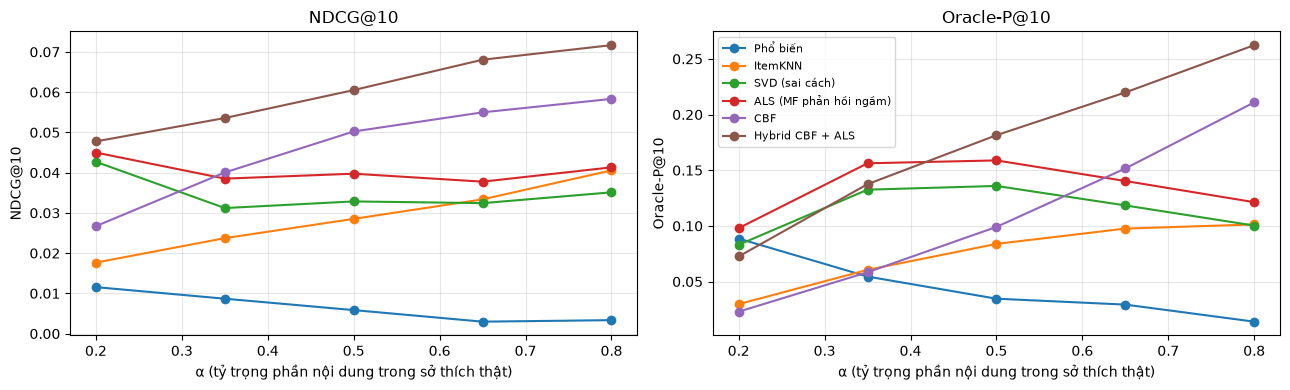

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Oracle-P@10']):
    for name in ['Phổ biến', 'ItemKNN', 'SVD (sai cách)', 'ALS (MF phản hồi ngầm)', 'CBF', 'Hybrid CBF + ALS']:
        ax.plot(ALPHAS, sens[metric].unstack().loc[ALPHAS, name], marker='o', label=name)
    ax.set(title=metric, xlabel='α (tỷ trọng phần nội dung trong sở thích thật)', ylabel=metric)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Lưu bộ dữ liệu mô phỏng
Lưu vào `data/simulated/` (thư mục `data/` không đưa lên git; chạy lại notebook sẽ sinh lại y hệt nhờ cố định `SEED`).

| File | Nội dung |
|---|---|
| `users.csv` | hồ sơ người dùng; các cột `taste_cluster`, `taste`, `brand_sens` là **phần ẩn**, chỉ dùng để phân tích |
| `jobs_hidden.csv` | `job_id`, nhóm nghề, vòng đời, loại công ty, thương hiệu, độ hấp dẫn (**ẩn**) |
| `impressions.csv` | mọi lượt hiển thị: người dùng, tin, ngày, vị trí, nguồn |
| `interactions_alpha0.5.csv` | sự kiện bấm / lưu / ứng tuyển ở $\alpha = 0{,}5$ |
| `true_utility_alpha0.5.npy` | ma trận $U(u, j)$ thật, **chỉ dùng để chấm điểm** |
| `config.json` | toàn bộ tham số mô phỏng |

In [16]:
os.makedirs(OUT_DIR, exist_ok=True)
u_out = users.copy()
u_out['skills'] = u_out['skills'].map(', '.join)
u_out['taste'] = u_out['taste'].map(lambda t: json.dumps([round(float(x), 4) for x in t]))
u_out.to_csv(os.path.join(OUT_DIR, 'users.csv'), index=False, encoding='utf-8')
jh = jobs[['job_id', 'domain', 'open_day', 'close_day', 'company_type', 'brand', 'quality']].copy()
jh['company_type'] = jh['company_type'].map(dict(enumerate(COMPANY_TYPES)))
jh.to_csv(os.path.join(OUT_DIR, 'jobs_hidden.csv'), index=False, encoding='utf-8')
job_ids = jobs['job_id'].to_numpy(dtype=object)
impressions.assign(job_id=job_ids[impressions.job_idx])[['user_id', 'job_id', 'day', 'position', 'source']] \
    .to_csv(os.path.join(OUT_DIR, 'impressions.csv'), index=False)
events_05.assign(job_id=job_ids[events_05.job_idx])[['user_id', 'job_id', 'day', 'position', 'source', 'event', 'weight']] \
    .to_csv(os.path.join(OUT_DIR, 'interactions_alpha0.5.csv'), index=False)
np.save(os.path.join(OUT_DIR, 'true_utility_alpha0.5.npy'), true_utility(0.5).astype(np.float16))
config = {'seed': SEED, 'n_users': N_USERS, 'n_days': N_DAYS, 'job_open_days': JOB_OPEN_DAYS, 'snapshot': str(SNAPSHOT.date()),
          'taste_clusters': N_TASTE_CLUSTERS, 'company_types': COMPANY_TYPES, 'slate': SLATE, 'event_weight': EVENT_WEIGHT,
          'test_start_day': TEST_START, 'utility': 'alpha*z(content) + (1-alpha)*z(hidden)'}
with open(os.path.join(OUT_DIR, 'config.json'), 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
for fn in sorted(os.listdir(OUT_DIR)):
    print(f"  {fn:32s} {os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e6:6.1f} MB")

  config.json                         0.0 MB
  impressions.csv                    14.2 MB
  interactions_alpha0.5.csv           1.1 MB
  jobs_hidden.csv                     0.3 MB
  true_utility_alpha0.5.npy          20.8 MB
  users.csv                           0.5 MB


## 8. Kết luận

Ô dưới **tự kiểm tra lại từng nhận định** trên kết quả của lần chạy hiện tại. Khi crawl thêm dữ liệu và chạy lại, hãy đọc ô này trước: phần chữ phía dưới ghi số liệu của lần chạy đầu tiên (dữ liệu chụp ngày 05/11/2026).

In [17]:
def check(label, ok, detail):
    print(f"[{'ĐÚNG' if ok else 'KHÔNG CÒN ĐÚNG'}] {label}: {detail}")

r, orac, nd = res_05, sens['Oracle-P@10'].unstack(), sens['NDCG@10'].unstack()
ALS, CBF, HYB, SVD = 'ALS (MF phản hồi ngầm)', 'CBF', 'Hybrid CBF + ALS', 'SVD (sai cách)'
print(f"Dữ liệu chụp ngày {SNAPSHOT.date()}, {len(jobs):,} tin, {len(events_05):,} sự kiện ở α = 0,5\n")
check("ALS hơn SVD ở α = 0,5 (Oracle-P@10)", r.loc[ALS, 'Oracle-P@10'] > r.loc[SVD, 'Oracle-P@10'],
      f"{r.loc[ALS, 'Oracle-P@10']:.3f} so với {r.loc[SVD, 'Oracle-P@10']:.3f}")
cold_share = (~split_05['warm_items'] & split_05['cand']).sum() / split_05['cand'].sum()
check("ALS không gợi ý được tin mới", r.loc[ALS, 'Recall@10 tin mới'] == 0,
      f"Recall@10 tin mới = {r.loc[ALS, 'Recall@10 tin mới']:.3f}; {cold_share:.0%} tin ứng viên chưa có tương tác ở train")
check("Hybrid có NDCG@10 cao nhất ở mọi α", bool((nd.idxmax(axis=1) == HYB).all()),
      ", ".join(f"α={a}: {m}" for a, m in nd.idxmax(axis=1).items()))
check("Hybrid giữ được tin mới", r.loc[HYB, 'Recall@10 tin mới'] > 0,
      f"{r.loc[HYB, 'Recall@10 tin mới']:.3f} (CBF {r.loc[CBF, 'Recall@10 tin mới']:.3f})")
als_wins_oracle = [a for a in ALPHAS if orac.loc[a, ALS] > orac.loc[a, CBF]]
als_wins_log = [a for a in ALPHAS if nd.loc[a, ALS] > nd.loc[a, CBF]]
check("Log thiên vị CBF (ALS thắng CBF theo sở thích thật ở nhiều mức α hơn so với theo log)",
      len(als_wins_oracle) > len(als_wins_log),
      f"ALS > CBF theo Oracle ở α = {als_wins_oracle}, theo log ở α = {als_wins_log}")

Dữ liệu chụp ngày 2026-11-05, 3,470 tin, 24,581 sự kiện ở α = 0,5

[ĐÚNG] ALS hơn SVD ở α = 0,5 (Oracle-P@10): 0.159 so với 0.136
[ĐÚNG] ALS không gợi ý được tin mới: Recall@10 tin mới = 0.000; 43% tin ứng viên chưa có tương tác ở train
[ĐÚNG] Hybrid có NDCG@10 cao nhất ở mọi α: α=0.2: Hybrid CBF + ALS, α=0.35: Hybrid CBF + ALS, α=0.5: Hybrid CBF + ALS, α=0.65: Hybrid CBF + ALS, α=0.8: Hybrid CBF + ALS
[ĐÚNG] Hybrid giữ được tin mới: 0.094 (CBF 0.099)
[ĐÚNG] Log thiên vị CBF (ALS thắng CBF theo sở thích thật ở nhiều mức α hơn so với theo log): ALS > CBF theo Oracle ở α = [0.2, 0.35, 0.5], theo log ở α = [0.2]


**1. ALS (MF cho phản hồi ngầm) là mô hình CF tốt nhất ở đây, nhưng không dùng một mình được.**
- ALS hơn SVD "sai cách" và ItemKNN ở gần như mọi mức $\alpha$, trên cả hai thước đo. Ở $\alpha = 0{,}5$: Oracle-P@10 0,159 so với 0,136 (SVD) và 0,084 (ItemKNN).
- Nhưng ALS **không gợi ý được tin mới** (Recall@10 trên tin mới = 0): khoảng 43% tin ứng viên ở giai đoạn test chưa có tương tác nào ở train. Với tin tuyển dụng, vòng đời chỉ vài tuần, đây là điểm yếu chí mạng.
- Độ phủ của ALS chỉ ~10%: nó dồn gợi ý vào nhóm tin đã có nhiều tương tác.

**2. Hybrid CBF + ALS an toàn nhất.**
- Hybrid có NDCG@10 cao nhất ở **mọi** mức $\alpha$, và Oracle-P@10 cao nhất từ $\alpha = 0{,}5$ trở lên.
- Nhờ quy tắc "tin mới chỉ dùng CBF", Hybrid giữ được khả năng gợi ý tin mới (0,094, gần bằng CBF 0,099).
- Ngoại lệ: khi sở thích gần như toàn phần ẩn ($\alpha = 0{,}2$), ALS thuần (0,098) hơn Hybrid (0,073) vì trọng số $w_{CBF} = 0{,}7$ chọn ở $\alpha = 0{,}5$ là quá cao cho trường hợp này.

**3. Bài học về đánh giá: log hành vi bị thiên lệch theo hệ thống đã hiển thị.**
- Theo **sở thích thật** (Oracle-P@10), ALS hơn CBF khi $\alpha \le 0{,}5$ (vd. 0,159 so với 0,099 ở $\alpha = 0{,}5$).
- Theo **log** (NDCG@10), CBF lại hơn ALS ngay từ $\alpha = 0{,}35$.
- Lý do: 6/20 tin mỗi phiên do một hệ **dựa trên nội dung** chọn, nên người dùng chủ yếu *được thấy* (và bấm) các tin khớp nội dung. Đánh giá trên log vì thế thiên vị CBF.
- Nếu sau này có log thật, cần tính đến thiên lệch này (vd. *inverse propensity scoring* với cột `source` và `position` đã lưu trong `impressions.csv`).

**4. Nên dùng kết quả này như thế nào?**
- Kết luận chỉ đúng **dưới giả định mô phỏng**: khẩu vị theo 6 cụm, 4 loại công ty, các hằng số của phễu hành vi. Giá trị tuyệt đối của các chỉ số không có ý nghĩa; chỉ nên đọc **xu hướng và thứ tự** giữa các mô hình.
- Hướng đi hợp lý cho dự án: giữ CBF (notebook 05) làm nền vì nó xử lý được tin mới, và thêm ALS khi có log thật, kết hợp theo kiểu Hybrid ở trên.
- Bước tiếp theo nếu muốn: BPR (học thứ hạng từ cặp tin đã bấm / tin bị bỏ qua, dùng được bảng `impressions`), MF có đặc trưng nội dung kiểu LightFM (để tin mới cũng có vector), và chọn $w_{CBF}$ theo số tương tác của từng người dùng.